# Problem 6.2

## Part 0

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Create Lagrange interpolation function

# xnodes and ynodes are lists, x is where we are interpolating
def Lagrange(xnodes, ynodes, x):
    # Add up all the yiLi
    sum = 0

    # Robust portion, make sure that xnodes and ynodes have same length
    if len(xnodes) != len(ynodes):
        raise ValueError("xnodes and ynodes must have the same length")
    
    # Iterate through the range of xnodes
    for i in range(len(xnodes)):

        # Starting value for Lagrange basis functions
        Li = 1

        for j in range(len(xnodes)):
            # In the case when i and j are equal, they look at the same xnode
            if i == j:
                continue

            # Numerator of the Lagrange basis function
            numerator = x - xnodes[j]
            denominator = xnodes[i] - xnodes[j]

            Li = Li * (numerator / denominator)
    
        # Add up all products of the Lagrange basis functions and y
        sum = sum + ynodes[i] * Li

    return sum


## Part 1

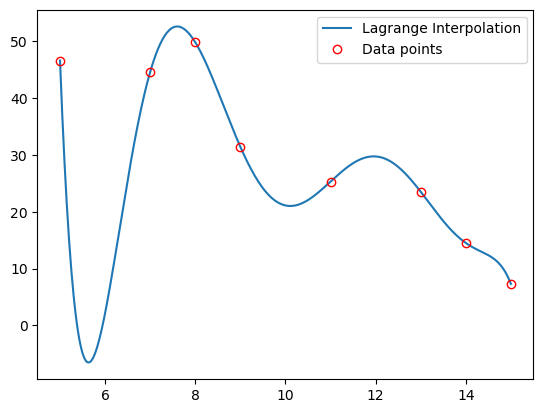

In [21]:
# Plot y = Lagrange and plot each point

# Initialize xnodes and ynodes
xnodes = [5,7,8,9,11,13,14,15]
ynodes = [46.6,44.6,49.8,31.4,25.3,23.5,14.5,7.3]

# Linespace: starting, ending, number of points
x = np.linspace(5, 15, 401)
y = Lagrange(xnodes, ynodes, x)

plt.plot(x, y, label="Lagrange Interpolation")
plt.plot(xnodes, ynodes, 'o', markerfacecolor='none', markeredgecolor='red', label="Data points")
plt.legend()


## Part 2

In [22]:
# Using the interpolating polynomial, estimate the average daily temperature for:
# Feb. 1, 4, 6, 10, 12, 16, 18, March 1

# Recall february has 28 days, so march 1 is 29
x_interpolate = [1,4,6,10,12,16,18,29]

# Let y_interpolate be the list of interpolated values
y_interpolate = [Lagrange(xnodes, ynodes, x) for x in x_interpolate]

# Print each value 
for i, value in enumerate(y_interpolate):
    if x_interpolate[i] == 29:
        print(f"Date: March 1, Predicted: {value:.2f}°F")
    else:
        print(f"Date: February {x_interpolate[i]}, Predicted: {value:.2f}°F")

Date: February 1, Predicted: 24919.90°F
Date: February 4, Predicted: 664.21°F
Date: February 6, Predicted: 2.16°F
Date: February 10, Predicted: 21.10°F
Date: February 12, Predicted: 29.72°F
Date: February 16, Predicted: -84.44°F
Date: February 18, Predicted: -2534.14°F
Date: March 1, Predicted: -3405976.70°F


## Part 3

In [23]:
# Calculate errors
actual = [44.3,57.3,45.6,28.6,23.2,17.5,25.3,50.4]

# Recall from 5 to 15
for i in range(len(actual)):
    if 5 <= x_interpolate[i] <= 15:
        print(f"Interpolation error (inside 5 to 15): {actual[i]-y_interpolate[i]:.2f}")
    else:
        print(f"Extrapolation error (outside 5 to 15): {actual[i]-y_interpolate[i]:.2f}")

Extrapolation error (outside 5 to 15): -24875.60
Extrapolation error (outside 5 to 15): -606.91
Interpolation error (inside 5 to 15): 43.44
Interpolation error (inside 5 to 15): 7.50
Interpolation error (inside 5 to 15): -6.52
Extrapolation error (outside 5 to 15): 101.94
Extrapolation error (outside 5 to 15): 2559.44
Extrapolation error (outside 5 to 15): 3406027.10



Interpolation within the original interval $[5,15]$ generally produces smaller errors than extrapolation, although some estimates remain inaccurate. For example, the February 6 estimate differs from the actual temperature by approximately $43.44^\circ\mathrm{F}$. This may be attributed to oscillations in the degree-7 interpolating polynomial.

Extrapolation outside the interval produces much larger errors, particularly at February 1 and March 1, where the predicted temperatures are physically unrealistic. Therefore, polynomial interpolation is not guaranteed to provide accurate estimates between known data points, while extrapolation using this polynomial is especially unreliable.


## Part 4

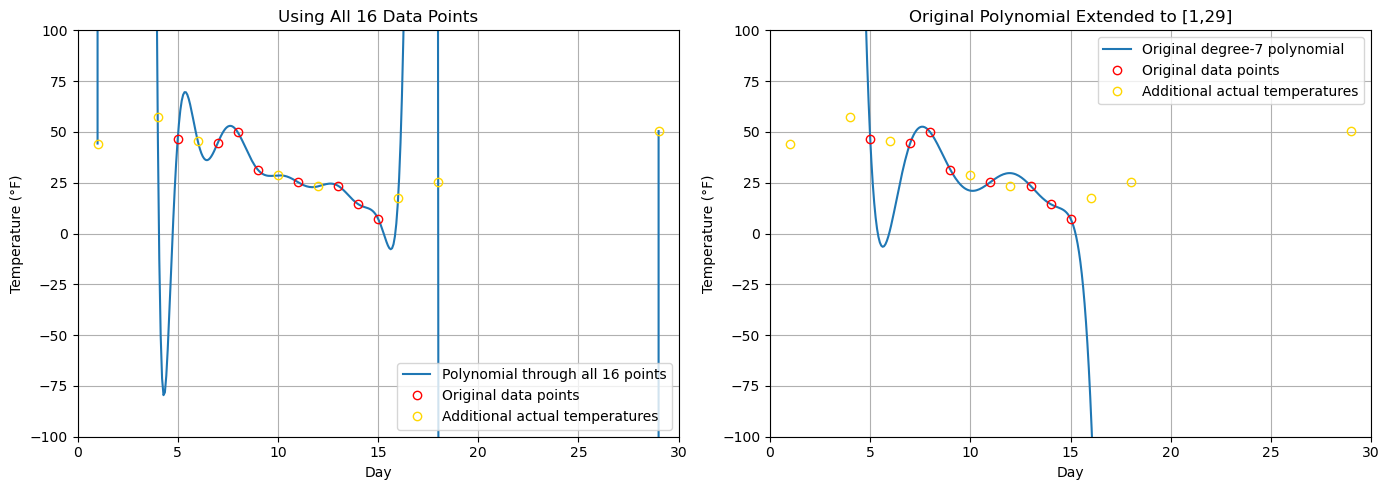

In [24]:
# Compare both interpretations side by side

import numpy as np
import matplotlib.pyplot as plt

# Original data points from the problem
xnodes = [5, 7, 8, 9, 11, 13, 14, 15]
ynodes = [46.6, 44.6, 49.8, 31.4, 25.3, 23.5, 14.5, 7.3]

# Additional dates and actual temperatures from part (3)
x_interpolate = [1, 4, 6, 10, 12, 16, 18, 29]
actual = [44.3, 57.3, 45.6, 28.6, 23.2, 17.5, 25.3, 50.4]

# Combined data for the "new polynomial" interpretation
new_xnodes = xnodes + x_interpolate
new_ynodes = ynodes + actual

# Plotting interval
x = np.linspace(1, 29, 401)

# LEFT GRAPH: new polynomial through all 16 points
y_all = Lagrange(new_xnodes, new_ynodes, x)

# RIGHT GRAPH: original polynomial from Part 1 extended to [1,29]
y_old = Lagrange(xnodes, ynodes, x)

# Create side-by-side plots
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# ---------------- LEFT: all 16 points ----------------
ax[0].plot(x, y_all, '-', label='Polynomial through all 16 points')
ax[0].plot(xnodes, ynodes, 'o', markerfacecolor='none',
           markeredgecolor='red', label='Original data points')
ax[0].plot(x_interpolate, actual, 'o', markerfacecolor='none',
           markeredgecolor='gold', label='Additional actual temperatures')

ax[0].set_xlim(0, 30)
ax[0].set_ylim(-100, 100)
ax[0].set_xlabel('Day')
ax[0].set_ylabel('Temperature (°F)')
ax[0].set_title('Using All 16 Data Points')
ax[0].legend()
ax[0].grid(True)

# ---------------- RIGHT: original polynomial ----------------
ax[1].plot(x, y_old, '-', label='Original degree-7 polynomial')
ax[1].plot(xnodes, ynodes, 'o', markerfacecolor='none',
           markeredgecolor='red', label='Original data points')
ax[1].plot(x_interpolate, actual, 'o', markerfacecolor='none',
           markeredgecolor='gold', label='Additional actual temperatures')

ax[1].set_xlim(0, 30)
ax[1].set_ylim(-100, 100)
ax[1].set_xlabel('Day')
ax[1].set_ylabel('Temperature (°F)')
ax[1].set_title('Original Polynomial Extended to [1,29]')
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

For comparison, the left plot shows a new interpolating polynomial constructed using all 16 available temperature data points, including the additional temperatures listed in part (3). Since this polynomial is constructed using all 16 measurements, it passes through each data point exactly. However, significant oscillations may still occur between the interpolation nodes, demonstrating that including additional points does not necessarily guarantee a more reliable polynomial model.

The right plot shows the original degree-7 Lagrange interpolating polynomial from part (1), extended over the interval $[1,29]$. This is the plot requested in part (4). It shows that while the polynomial interpolates the original eight data points exactly, its extrapolated behavior outside the interval $[5,15]$ becomes highly unrealistic. In particular, the curve rapidly leaves the plotted temperature range near the endpoints, supporting the conclusion from part (3) that extrapolation with a high-degree interpolating polynomial is unreliable.

Thus, the comparison highlights the difference between constructing a new interpolant using additional data and extending the original interpolating polynomial beyond its original interval.